# 🖼️ PID - Tema 2: TRANSFORMACIONES DE INTENSIDAD

---

## 🎯 Objetivos de Aprendizaje

- Histograma de una imagen
- Transformaciones lineales
- Transformación log
- Transformación exponencial
- Corrección gamma
- Ecualización y expansión del histograma
- Procesmiento de imágenes a color

In [1]:
import cv2 as cv 
import matplotlib.pyplot as plt 
import numpy as np

## 📝 Ejercicio 1: Histograma de una imagen

**Tarea:**  
Analizar los histogramas de imágenes en escala de grises con distintos niveles de grises y contrastes.

**Pasos / Orientación:**  
1. Carga varias imágenes en escala de grises: claras, oscuras, con mucho contraste, con poco contraste...  
2. Representa el histograma de cada una de ellas.
3. Observa la información que puedes obtener de las imágenes a partir de dichos histogramas.

Escribe tu solución en la celda siguiente:


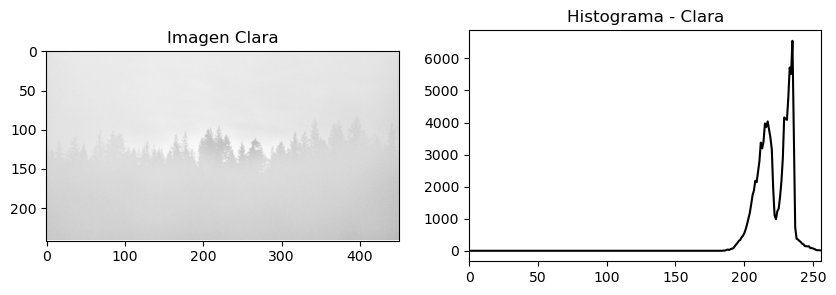

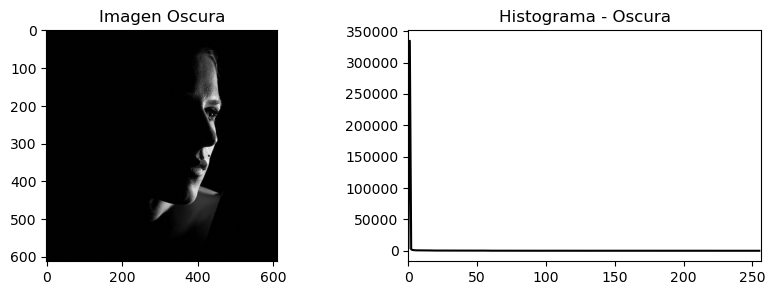

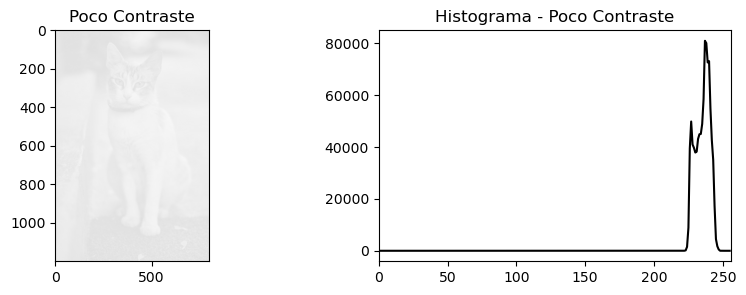

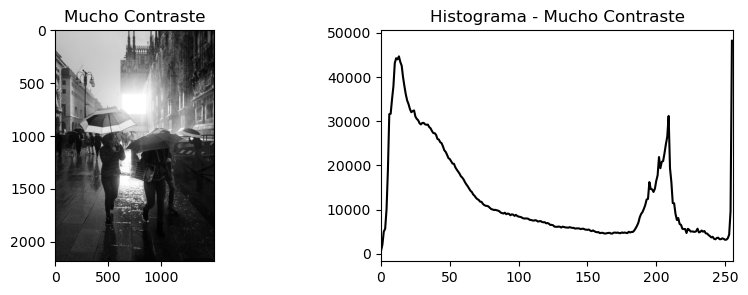

In [4]:
# ==========================================
# 1. IMAGEN CLARA (poco_contraste_clara.jpg)
# ==========================================
img_clara = cv.imread('poco_contraste_clara.jpg', 0)
hist_clara = cv.calcHist([img_clara], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.imshow(img_clara, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Clara')

plt.subplot(1, 2, 2)
plt.plot(hist_clara, color='black')
plt.title('Histograma - Clara')
plt.xlim([0, 256])
plt.show()

# ==========================================
# 2. IMAGEN OSCURA (poco_contraste_oscura.jpg)
# ==========================================
img_oscura = cv.imread('poco_contraste_oscura.jpg', 0)
hist_oscura = cv.calcHist([img_oscura], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.imshow(img_oscura, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Oscura')

plt.subplot(1, 2, 2)
plt.plot(hist_oscura, color='black')
plt.title('Histograma - Oscura')
plt.xlim([0, 256])
plt.show()

# ==========================================
# 3. IMAGEN CON POCO CONTRASTE (mujer.jpg)
# ==========================================
img_poco_c = cv.imread('gato_poco_contraste.jpg', 0)
hist_poco_c = cv.calcHist([img_poco_c], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.imshow(img_poco_c, cmap='gray', vmin=0, vmax=255)
plt.title('Poco Contraste')

plt.subplot(1, 2, 2)
plt.plot(hist_poco_c, color='black')
plt.title('Histograma - Poco Contraste')
plt.xlim([0, 256])
plt.show()

# ==========================================
# 4. IMAGEN CON MUCHO CONTRASTE (mucho_contraste.jpg)
# ==========================================
img_mucho_c = cv.imread('mucho_contraste.jpg', 0)
hist_mucho_c = cv.calcHist([img_mucho_c], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1)
plt.imshow(img_mucho_c, cmap='gray', vmin=0, vmax=255)
plt.title('Mucho Contraste')

plt.subplot(1, 2, 2)
plt.plot(hist_mucho_c, color='black')
plt.title('Histograma - Mucho Contraste')
plt.xlim([0, 256])
plt.show()

- Imagen clara: los picos de frecuencia están concentrados en el rango [190, 245]. Muestra que la imagen carece casi por completo de sombras o tonos oscuros. Es una imagen predominantemente clara y sobreexpuesta por la presencia de niebla.   

- Imagen oscura: presenta un enorme pico único en el valor 0 (negro). La mayoría de los píxeles de la escena pertenecen al fondo negro o zonas en sombra profunda. El histograma nos indica que hay muy poca información en la gama media y alta de grises.

- Poco contraste: todos los píxeles están amontonados entre 220 y 250.  Revela que no se está aprovechando el rango disponible (0 a 255). Al estar todos los valores comprimidos en un rango tan corto de grises claros, la imagen se percibe lavada y con detalles muy difíciles de distinguir a simple vista.

- Mucho contraste: tiene una distribución muy amplia a lo largo de todo el eje horizontal. Cuenta con un gran volumen de tonos oscuros (pico cerca del 20), tonos medios bien repartidos y un pico final en el 255 (luces ). Indica una imagen rica en detalles visuales, con gran profundidad, negros bien definidos y altas luces marcadas, aprovechando al máximo el rango dinámico disponible.   

## 📝 Ejercicio 2: Transformaciones lineales

**Tarea:**  
Realizar transformaciones lineales $T(r) = ar+b$ a una imagen digital.

**Pasos / Orientación:**  
1. Carga una imagen en escala de grises.  
2. Realiza transformaciones lineales variando los valores de los parámetros $a$ y $b$.
3. Analiza los resultados obtenidos.
   
Escribe tu solución en la celda siguiente:

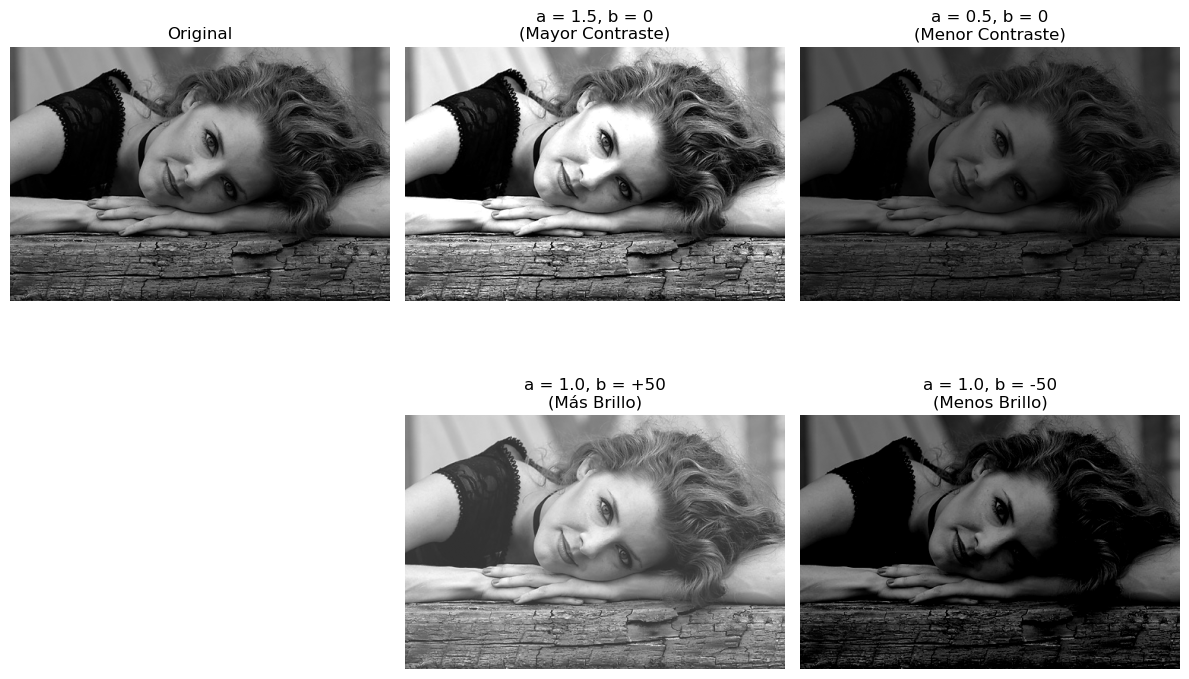

In [5]:
img = cv.imread('mujer.jpg', 0)
img_float = img.astype(np.float32)

# Caso 1: Aumentar contraste (a > 1)
img_t1 = np.clip(1.5 * img_float + 0, 0, 255).astype(np.uint8)

# Caso 2: Disminuir contraste (a < 1)
img_t2 = np.clip(0.5 * img_float + 0, 0, 255).astype(np.uint8)

# Caso 3: Aumentar brillo (b > 0)
img_t3 = np.clip(1.0 * img_float + 50, 0, 255).astype(np.uint8)

# Caso 4: Disminuir brillo (b < 0)
img_t4 = np.clip(1.0 * img_float - 50, 0, 255).astype(np.uint8)

# 3. Mostrar los resultados
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_t1, cmap='gray', vmin=0, vmax=255)
plt.title('a = 1.5, b = 0\n(Mayor Contraste)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_t2, cmap='gray', vmin=0, vmax=255)
plt.title('a = 0.5, b = 0\n(Menor Contraste)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_t3, cmap='gray', vmin=0, vmax=255)
plt.title('a = 1.0, b = +50\n(Más Brillo)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_t4, cmap='gray', vmin=0, vmax=255)
plt.title('a = 1.0, b = -50\n(Menos Brillo)')
plt.axis('off')

plt.tight_layout()
plt.show()

- Efecto de la pendiente a (contraste):
  - $a = 1.5$ ($a > 1$): aumenta el contraste al amplificar las diferencias entre tonos claros y oscuros. La piel se observa más brillante y las sombras se acentúan.
  - $a = 0.5$ ($a < 1$): reduce el contraste al comprimir todo el rango dinámico, resultando en una imagen más apagada o grisácea.

- Efecto del desplazamiento b (brillo):
  - $b = +50$ ($b > 0$): aumenta el brillo global desplazando la intensidad de todos los píxeles uniformemente hacia el blanco. Las zonas oscuras se vuelven grises.
  - $b = -50$ ($b < 0$): disminuye el brillo global desplazando la intensidad hacia el negro, provocando una pérdida de detalle en las sombras.

## 📝 Ejercicio 3: Transformación log
**Tarea:**  
Realizar la transformación *log* a una imagen y analizar el efecto que produce.

$s = T(r) = C log(1 + r)$

**Pasos / Orientación:**  
1. Carga una imagen en escala de grises que tenga zonas con bajo nivel de intensidad.  
2. Realiza la transformación *log* a dicha imagen. 
3. Analiza el efecto que produce en dichas zonas.

Escribe tu solución en la celda siguiente:

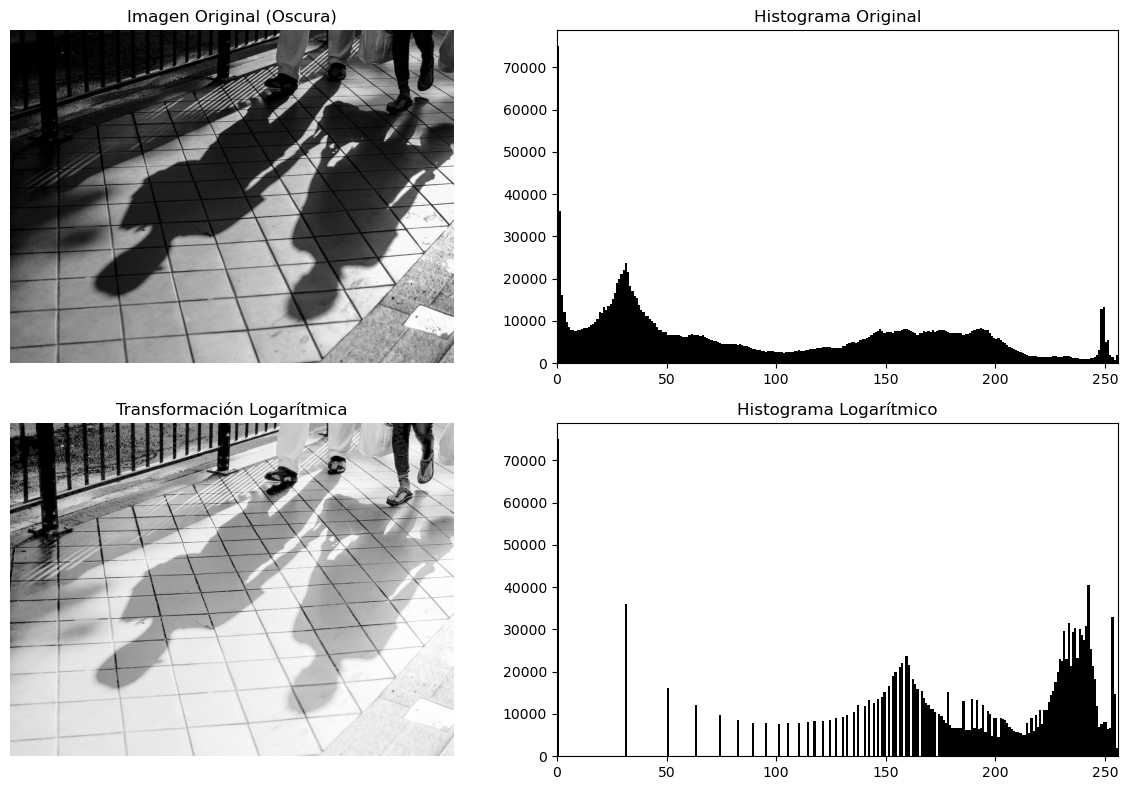

In [14]:
# 1. Cargar una imagen con zonas de bajo nivel de intensidad (oscura)
img = cv.imread('sombras.jpg', cv.IMREAD_GRAYSCALE)

# 2. Aplicar la transformación logarítmica: s = C * log(1 + r)
img_float = img.astype(np.float32)

# Calcular constante C = 255 / log(1 + max_pixel)
C = 255 / np.log(1 + np.max(img_float))

# Aplicar la fórmula T(r) = C * log(1 + r)
img_log = C * np.log(1 + img_float)
img_log = np.uint8(img_log)

# 3. Mostrar la imagen original y la transformada junto con sus histogramas
plt.figure(figsize=(12, 8))

# Imagen Original
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Original (Oscura)')
plt.axis('off')

# Histograma Original (range corregido como keyword argument)
plt.subplot(2, 2, 2)
plt.hist(img.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Original')
plt.xlim([0, 256])

# Imagen Transformada (Log)
plt.subplot(2, 2, 3)
plt.imshow(img_log, cmap='gray', vmin=0, vmax=255)
plt.title('Transformación Logarítmica')
plt.axis('off')

# Histograma Transformado (range corregido como keyword argument)
plt.subplot(2, 2, 4)
plt.hist(img_log.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Logarítmico')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

- Aclarado de zonas oscuras: la curva logarítmica expande los valores de intensidad bajos (cercanos a $0$). Como se aprecia en la imagen, el suelo dentro de la sombra de las personas pasa de ser prácticamente negro a un tono gris claro, revelando los detalles de las baldosas y las texturas que antes estaban ocultas.
- Compresión de zonas claras: las altas luces (las losas expuestas directamente al sol) sufren una compresión en la parte alta de la curva, evitando que se quemen o pierdan información.
- Desplazamiento del histograma: En el histograma logarítmico se observa cómo la gran acumulación de píxeles oscuros (pico situado entre $0$ y $50$) se desplaza hacia la zona media y alta del rango dinámico (concentrándose entre $150$ y $240$). 

## 📝 Ejercicio 4: Transformación exponencial
**Tarea:**  
Realizar la transformación *exponencial* a una imagen y analizar el efecto que produce.

$s = T(r) = e^{r/c}-1$

**Pasos / Orientación:**  
1. Carga una imagen en escala de grises.  
2. Realiza la transformación *exponencial* a dicha imagen. 
3. Analiza el efecto que produce.

Escribe tu solución en la celda siguiente:

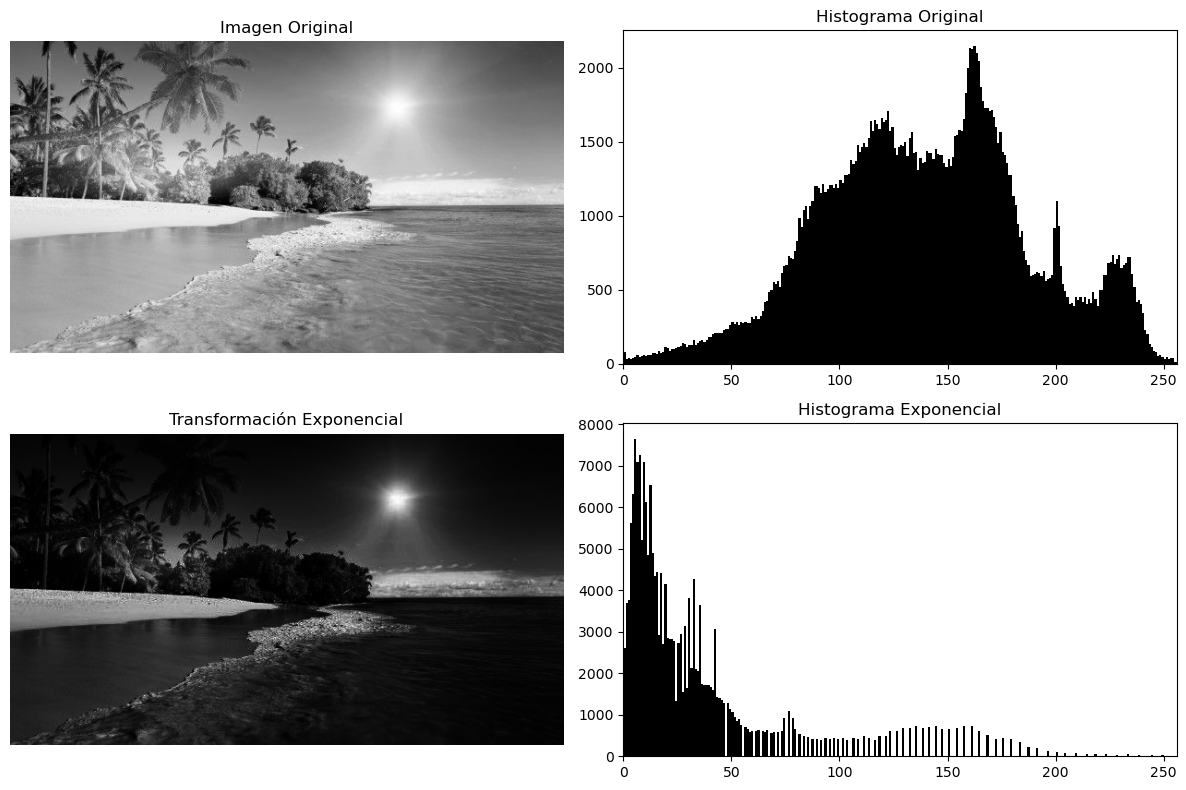

In [15]:
# TRANSFORMACIÓN EXPONENCIAL: T(r) = C * (a^r - 1)
#
# r -> Intensidad del píxel original.
# a -> Base exponencial (a > 1).
#
# EFECTO: Es el inverso del logaritmo. Oscurece los tonos medios y oscuros,
#        mientras que EXPANDE y da más contraste a las zonas BRILLANTES.
# USO: Resaltar objetos/detalles muy claros sobre fondos oscuros.

# 1. Cargar una imagen clara (o con brillo alto/sobreexpuesta)
img = cv.imread('playa.jpg', cv.IMREAD_GRAYSCALE)

# 2. Aplicar la transformación exponencial: s = e^(r/c) - 1
img_float = img.astype(np.float32)

# Se calcula el parámetro c para escalar la salida al rango [0, 255]
# 255 = e^(255/c) - 1  =>  c = 255 / ln(256)
c = 255.0 / np.log(256.0)

# Aplicar la función s = exp(r / c) - 1
img_exp = np.exp(img_float / c) - 1.0

# Asegurar rango de salida y convertir a uint8
img_exp = np.clip(img_exp, 0, 255).astype(np.uint8)

# 3. Mostrar la imagen original y la transformada junto con sus histogramas
plt.figure(figsize=(12, 8))

# Imagen Original
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Original')
plt.axis('off')

# Histograma Original
plt.subplot(2, 2, 2)
plt.hist(img.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Original')
plt.xlim([0, 256])

# Imagen Transformada (Exponencial)
plt.subplot(2, 2, 3)
plt.imshow(img_exp, cmap='gray', vmin=0, vmax=255)
plt.title('Transformación Exponencial')
plt.axis('off')

# Histograma Transformado
plt.subplot(2, 2, 4)
plt.hist(img_exp.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Exponencial')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

- Compresión de tonos oscuros y medios: la pendiente de la curva exponencial cerca del origen es casi plana, lo que provoca que una amplia gama de niveles de gris bajos y medios se compriman hacia valores de intensidad cercanos a $0$. Esto resulta en un oscurecimiento generalizado de las sombras (como la vegetación y la arena).
- Expansión de tonos claros: la curva adquiere mucha mayor pendiente en los valores altos de intensidad. Esto aumenta el contraste entre las zonas más brillantes (el sol y el cielo), permitiendo definir mejor las zonas que estaban muy expuestas.
- Impacto en el histograma: en la imagen original, la mayor parte de los píxeles estaban concentrados en tonos medios-altos ($100$ a $200$). Tras la transformación exponencial, la masa de información se desplaza hacia la izquierda, acumulándose entre los valores $0$ y $50$.

## 📝 Ejercicio 5: Transformación potencia - Corrección gamma
**Tarea:**  
Realizar la transformación *exponencial* a una imagen y analizar el efecto que produce.

$s = T(r) = C r^\gamma$

**Pasos / Orientación:**  
1. Carga dos imágenes en escala de grises con poco contraste, una clara y otra oscura.   
2. Realiza la transformación *gamma* a la imagen clara para distintos valores de $\gamma > 1$ y analiza los resultados. 
3. Realiza la transformación *gamma* a la imagen oscura para distintos valores de $\gamma < 1$ y analiza los resultados.

Escribe tu solución en la celda siguiente:


 DIFERENCIA GAMMA VS EXPONENCIAL:

 - GAMMA (r^gamma): Muy flexible. Con gamma < 1 aclara sombras; con gamma > 1 oscurece.
 - EXPONENCIAL (a^r - 1): Es el inverso estricto del logaritmo. Siempre oscurece tonos medios/bajos
  y expande únicamente las zonas de alto brillo de forma más agresiva que la Gamma.

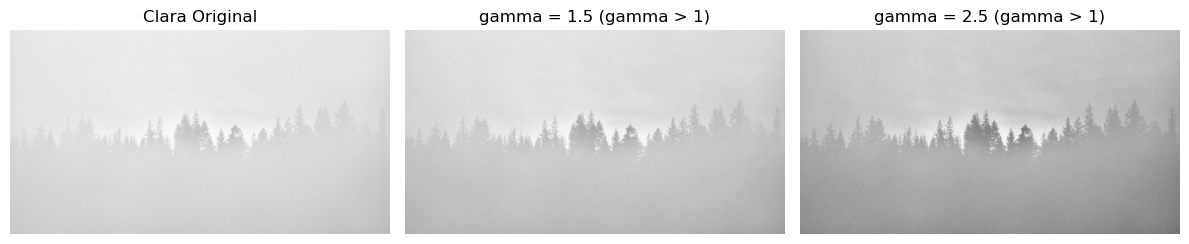

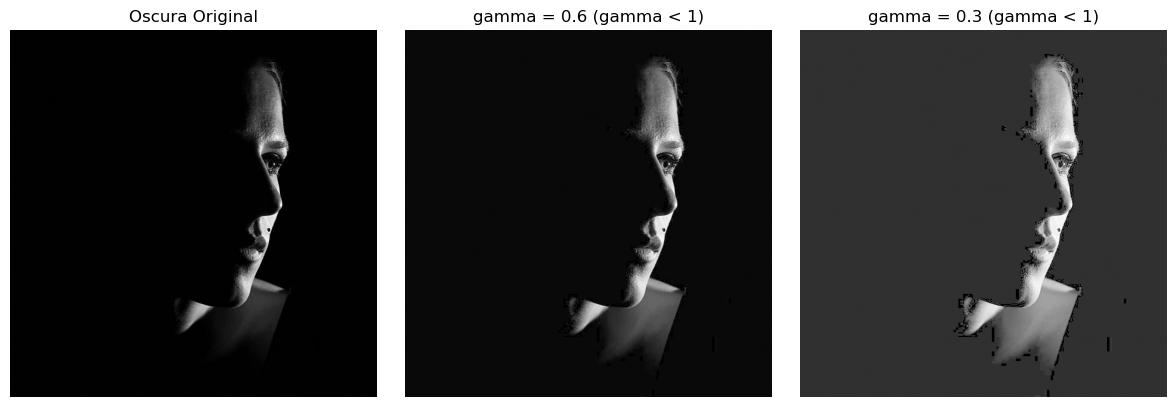

In [16]:
def aplicar_gamma(img, gamma):
    # Normalizar a [0, 1]
    img_norm = img / 255.0
    # Aplicar la función s = c * r^gamma (con c = 1)
    img_gamma = np.power(img_norm, gamma)
    # Escalar a [0, 255] y convertir a uint8
    return np.uint8(img_gamma * 255)

# 1. Cargar las dos imágenes de poco contraste (clara y oscura)
img_clara = cv.imread('poco_contraste_clara.jpg', cv.IMREAD_GRAYSCALE)
img_oscura = cv.imread('poco_contraste_oscura.jpg', cv.IMREAD_GRAYSCALE)

# --- Caso A: Imagen Clara con gamma > 1 ---
g_clara_1 = aplicar_gamma(img_clara, 1.5)
g_clara_2 = aplicar_gamma(img_clara, 2.5)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_clara, cmap='gray', vmin=0, vmax=255)
plt.title('Clara Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(g_clara_1, cmap='gray', vmin=0, vmax=255)
plt.title('gamma = 1.5 (gamma > 1)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(g_clara_2, cmap='gray', vmin=0, vmax=255)
plt.title('gamma = 2.5 (gamma > 1)')
plt.axis('off')

plt.tight_layout()
plt.show()

# --- Caso B: Imagen Oscura con gamma < 1 ---
g_oscura_1 = aplicar_gamma(img_oscura, 0.6)
g_oscura_2 = aplicar_gamma(img_oscura, 0.3)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_oscura, cmap='gray', vmin=0, vmax=255)
plt.title('Oscura Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(g_oscura_1, cmap='gray', vmin=0, vmax=255)
plt.title('gamma = 0.6 (gamma < 1)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(g_oscura_2, cmap='gray', vmin=0, vmax=255)
plt.title('gamma = 0.3 (gamma < 1)')
plt.axis('off')

plt.tight_layout()
plt.show()

- Imagen Clara con $\gamma > 1$: al aplicar valores de $\gamma > 1$ ($1.5$ y $2.5$), la curva de transformación se arquea hacia abajo, reduciendo las intensidades medias y altas.   Esto corrige el aspecto "lavado" del bosque con niebla, aumentando el contraste y haciendo visible el silueteado de los árboles. A mayor valor de $\gamma$, más se oscurece la imagen.
- Imagen Oscura con $\gamma < 1$: con valores de $\gamma < 1$ ($0.6$ y $0.3$), la curva se arquea hacia arriba, expandiendo los tonos oscuros cercanos al $0$. Con $\gamma = 0.6$ se aclaran las sombras del rostro de forma natural. Con un valor muy agresivo como $\gamma = 0.3$, el fondo negro pasa a ser gris claro, revelando todo el ruido y detalles ocultos. 

## 📝 Ejercicio 6: Expansión y ecualización del histograma
**Tarea:**  
Realizar la transformaciones *expansión* y *ecualización* del histograma a una imagen y analizar el efecto que produce.

**Pasos / Orientación:**  
1. Carga una imagen en escala de grises con poco contraste.  
2. Realiza las transformaciones *expansión* y *ecualización* al histograma de dicha imagen. 
3. Analiza el efecto que produce y visualiza los histogramas de las imágenes resultantes.

Escribe tu solución en la celda siguiente:

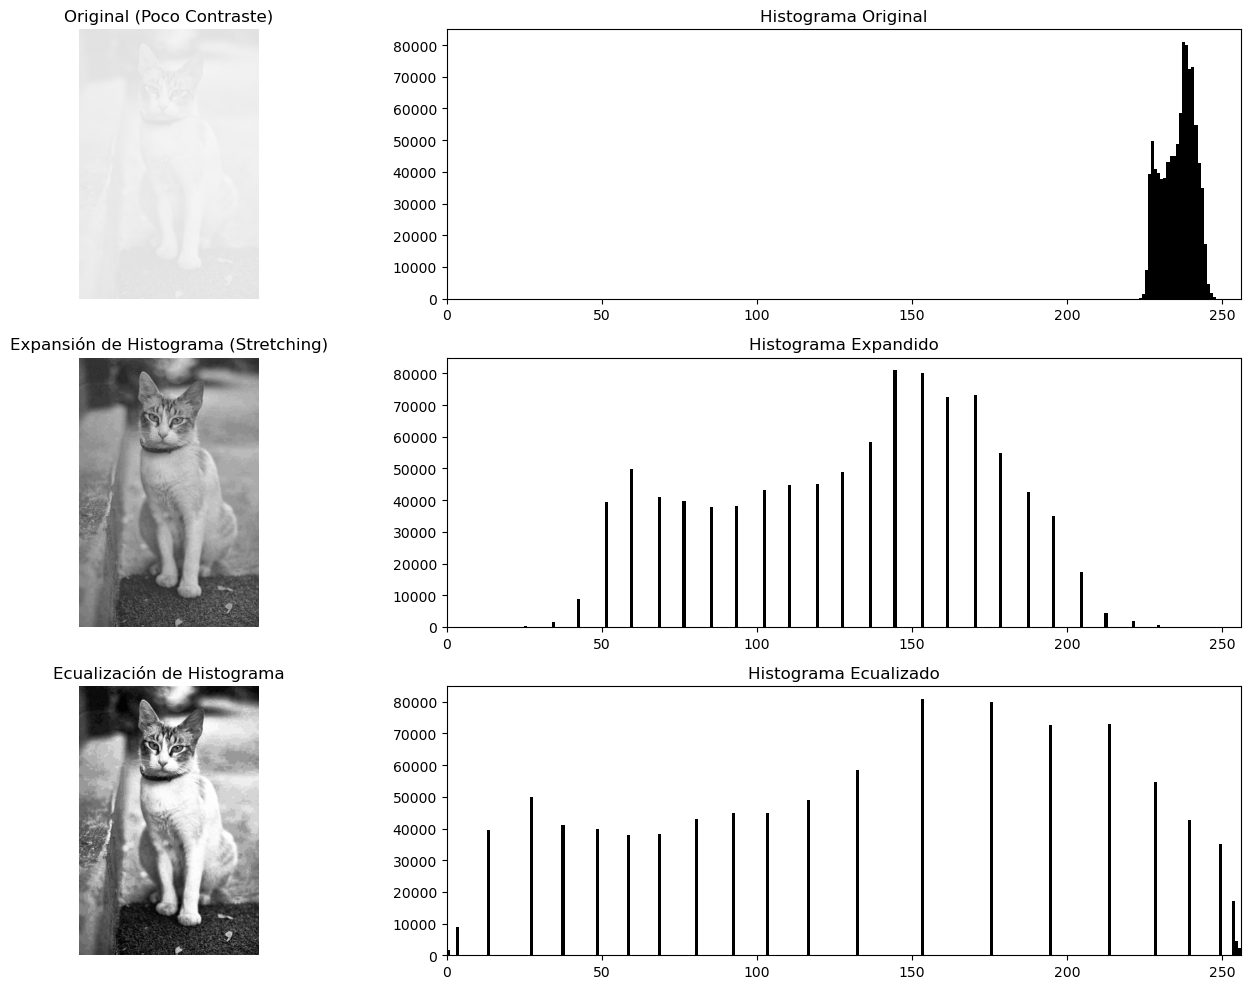

In [17]:

# 1. Cargar una imagen de poco contraste
img = cv.imread('gato_poco_contraste.jpg', cv.IMREAD_GRAYSCALE)

# 2. Transformación por Expansión (Stretching) lineal
# Formula: s = (r - min) * (255 / (max - min))
r_min = np.min(img)
r_max = np.max(img)
img_exp = ((img - r_min) / (r_max - r_min) * 255).astype(np.uint8)

# 3. Transformación por Ecualización (Equalization) usando OpenCV
img_eq = cv.equalizeHist(img)

# 4. Mostrar imágenes e histogramas
plt.figure(figsize=(15, 10))

# --- Original ---
plt.subplot(3, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original (Poco Contraste)')
plt.axis('off')

plt.subplot(3, 2, 2)
plt.hist(img.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Original')
plt.xlim([0, 256])

# --- Expansión ---
plt.subplot(3, 2, 3)
plt.imshow(img_exp, cmap='gray', vmin=0, vmax=255)
plt.title('Expansión de Histograma (Stretching)')
plt.axis('off')

plt.subplot(3, 2, 4)
plt.hist(img_exp.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Expandido')
plt.xlim([0, 256])

# --- Ecualización ---
plt.subplot(3, 2, 5)
plt.imshow(img_eq, cmap='gray', vmin=0, vmax=255)
plt.title('Ecualización de Histograma')
plt.axis('off')

plt.subplot(3, 2, 6)
plt.hist(img_eq.ravel(), 256, range=[0, 256], color='black')
plt.title('Histograma Ecualizado')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

- Expansión del histograma: mantiene las relaciones tonales originales pero aprovecha todo el rango dinámico ($0$ a $255$). El gato pasa de verse totalmente lavado y blanco a recuperar volumen natural, sombras y contraste sin saturar las altas luces. El histograma preserva la forma de frecuencias original, pero la estira y distribuye uniformemente sobre todo el eje horizontal ($30$ a $220$).
- Ecualización del histograma: maximiza el contraste global redistribuyendo los píxeles de acuerdo con la función de distribución acumulada. Aumenta drásticamente el detalle en el pelaje y el fondo, aunque acentúa un poco el ruido en el suelo. En el histograma, las barras verticales quedan distribuidas de manera más uniforme a lo largo de todo el espectro de $0$ a $255$, buscando una densidad de probabilidad plana. 

## 📝 Ejercicio 7: Transformaciones de imágenes a color
**Tarea:**  
Realizar transformaciones de intensidad una imagen a color usando los modelos RGB y HSV.

**Pasos / Orientación:**  
1. Carga una imagen a color.    
2. Realiza alguna de las transformaciones de intensidad anteriores a los canales del modelo RGB por separado y visualiza la imagen resultante.
3. Realiza la misma transformación al canal V del modelo HSV y visualiza la imagen resultante.

Escribe tu solución en la celda siguiente:

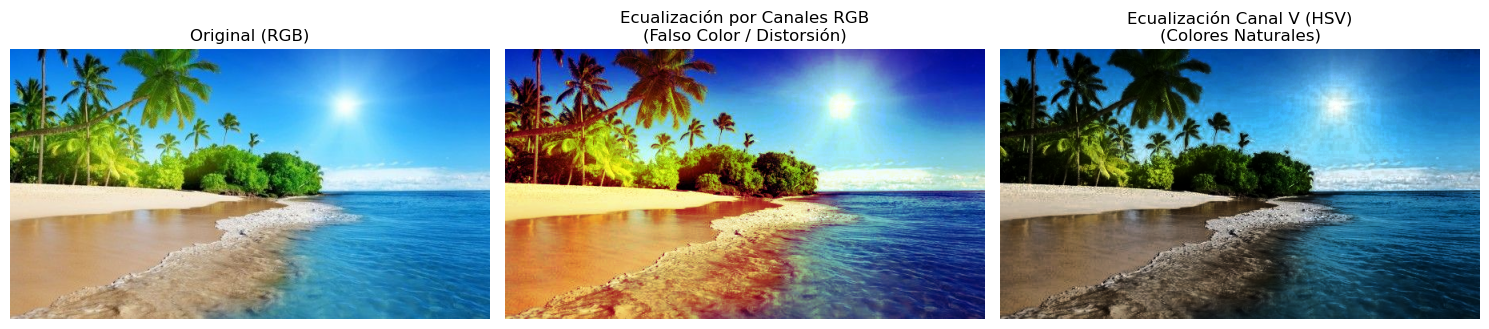

In [18]:
# 1. Cargar una imagen a color (OpenCV la lee por defecto en BGR)
img_bgr = cv.imread('playa.jpg')

# Convertir BGR a RGB para visualizar correctamente en Matplotlib
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# 2. Ecualización en canales RGB por separado
r, g, b = cv.split(img_rgb)
r_eq = cv.equalizeHist(r)
g_eq = cv.equalizeHist(g)
b_eq = cv.equalizeHist(b)
img_rgb_eq = cv.merge((r_eq, g_eq, b_eq))

# 3. Ecualización solo en el canal V del modelo HSV
img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)
h, s, v = cv.split(img_hsv)
v_eq = cv.equalizeHist(v)
img_hsv_eq = cv.merge((h, s, v_eq))
# Convertir de nuevo HSV a RGB para mostrar en Matplotlib
img_hsv_eq_rgb = cv.cvtColor(img_hsv_eq, cv.COLOR_HSV2RGB)

# 4. Mostrar resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Original (RGB)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_rgb_eq)
plt.title('Ecualización por Canales RGB\n(Falso Color / Distorsión)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_hsv_eq_rgb)
plt.title('Ecualización Canal V (HSV)\n(Colores Naturales)')
plt.axis('off')

plt.tight_layout()
plt.show()